In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, UpSampling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.utils import to_categorical

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training data:", x_train.shape)
print("Testing data :", x_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (60000, 28, 28)
Testing data : (10000, 28, 28)


In [ ]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

In [ ]:
input_img = Input(shape=(28, 28, 1))

Encoder

In [ ]:
x = Conv2D(32, (3, 3), activation="relu", padding="same")(input_img)
x = MaxPooling2D((2, 2), padding="same")(x)

x = Conv2D(64, (3, 3), activation="relu", padding="same")(x)
encoded = MaxPooling2D((2, 2), padding="same")(x)

In [ ]:
x = Conv2D(64, (3, 3), activation="relu", padding="same")(encoded)
x = UpSampling2D((2, 2))(x)

x = Conv2D(32, (3, 3), activation="relu", padding="same")(x)
x = UpSampling2D((2, 2))(x)

decoded = Conv2D(
    1,
    (3, 3),
    activation="sigmoid",
    padding="same"
)(x)



In [ ]:
autoencoder = Model(input_img, decoded)

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)


In [ ]:
history_ae = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=128,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 97s 205ms/step - loss: 0.1063 - val_loss: 0.0735
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 140s 201ms/step - loss: 0.0723 - val_loss: 0.0699
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 143s 204ms/step - loss: 0.0697 - val_loss: 0.0683
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 140s 201ms/step - loss: 0.0684 - val_loss: 0.0673
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 143s 203ms/step - loss: 0.0675 - val_loss: 0.0667
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 94s 201ms/step - loss: 0.0668 - val_loss: 0.0660
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 94s 201ms/step - loss: 0.0663 - val_loss: 0.0657
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 95s 202ms/step - loss: 0.0658 - val_loss: 0.0651
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 142s 202ms/step - loss: 0.0654 - val_loss: 0.0648
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 95s 202ms/step - loss: 0.0651 - val_loss: 0.0644


1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


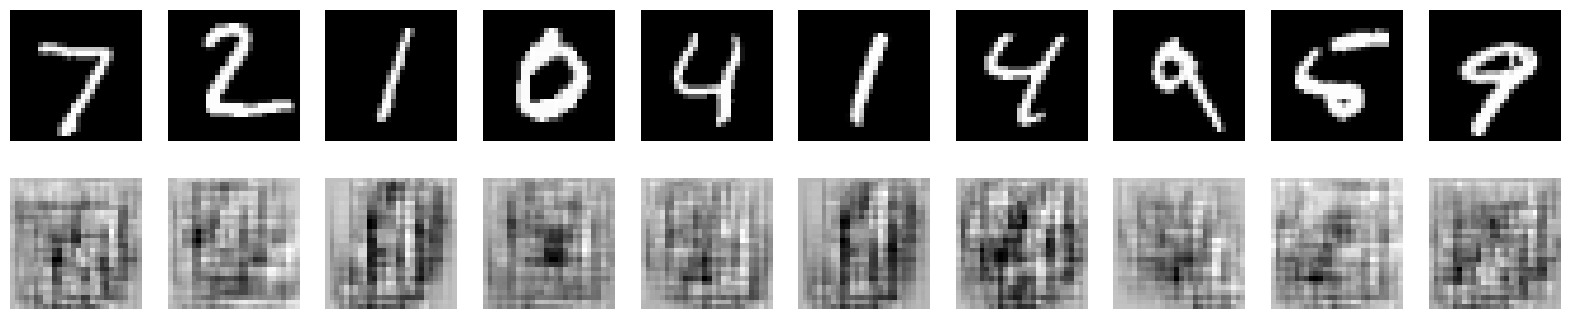

In [ ]:
decoded_imgs = autoencoder.predict(x_test[:10])

plt.figure(figsize=(20, 4))

for i in range(10):


    ax = plt.subplot(2, 10, i + 1)
    plt.imshow(x_test[i].squeeze(), cmap="gray")
    plt.axis("off")


    ax = plt.subplot(2, 10, i + 11)
    plt.imshow(decoded_imgs[i].squeeze(), cmap="gray")
    plt.axis("off")

plt.show()

In [ ]:
cnn_input = Input(shape=(7, 7, 64))

x = Conv2D(
    64,
    (3, 3),
    activation="relu",
    padding="same"
)(cnn_input)

x = MaxPooling2D((2, 2))(x)

x = Flatten()(x)

x = Dense(128, activation="relu")(x)

x = Dropout(0.5)(x)

output = Dense(10, activation="softmax")(x)

cnn = Model(cnn_input, output)

cnn.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["accuracy"]
)

In [ ]:
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)


In [ ]:
encoder = Model(input_img, encoded)

encoded_train = encoder.predict(x_train)
encoded_test = encoder.predict(x_test)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
history_cnn = cnn.fit(
    encoded_train,
    y_train_cat,
    epochs=10,
    batch_size=128,
    validation_data=(encoded_test, y_test_cat)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.8511 - loss: 0.4986 - val_accuracy: 0.9703 - val_loss: 0.1016
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9591 - loss: 0.1418 - val_accuracy: 0.9801 - val_loss: 0.0673
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9706 - loss: 0.1036 - val_accuracy: 0.9834 - val_loss: 0.0500
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9748 - loss: 0.0846 - val_accuracy: 0.9850 - val_loss: 0.0442
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9784 - loss: 0.0727 - val_accuracy: 0.9892 - val_loss: 0.0347
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9818 - loss: 0.0617 - val_accuracy: 0.9887 - val_loss: 0.0378
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9838 - loss: 0.0570 - val_accuracy: 0.9890 - val_loss: 0.0310
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9852 - loss: 0.0500 - val_accuracy: 0

In [ ]:
loss, accuracy = cnn.evaluate(
    encoded_test,
    y_test_cat
)

print("\nTest Loss:", loss)
print("Test Accuracy:", accuracy)


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9894 - loss: 0.0305

Test Loss: 0.030489761382341385
Test Accuracy: 0.9894000291824341


In [ ]:
predictions = cnn.predict(encoded_test)

predicted_labels = np.argmax(predictions, axis=1)

print("\nActual labels   :", y_test[:20])
print("Predicted labels:", predicted_labels[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Actual labels   : [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 3 4]
Predicted labels: [7 2 1 0 4 1 4 9 5 9 0 6 9 0 1 5 9 7 5 4]


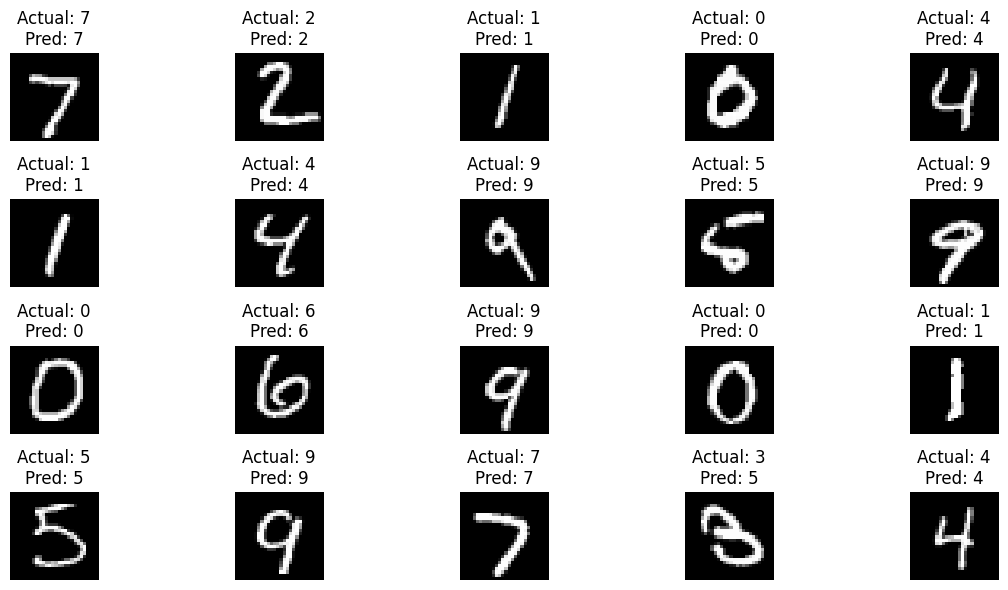

In [ ]:

plt.figure(figsize=(12, 6))

for i in range(20):

    ax = plt.subplot(4, 5, i + 1)

    plt.imshow(
        x_test[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]}\nPred: {predicted_labels[i]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
history_ae = autoencoder.fit(
    x_train,
    x_train,
    epochs=10,
    batch_size=128,
    shuffle=True,
    validation_data=(x_test, x_test)
)

Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - loss: 0.1039 - val_loss: 0.0736
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0720 - val_loss: 0.0698
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0696 - val_loss: 0.0687
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0682 - val_loss: 0.0672
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0672 - val_loss: 0.0667
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0665 - val_loss: 0.0658
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0660 - val_loss: 0.0653
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0656 - val_loss: 0.0649
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0652 - val_loss: 0.0647
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0648 - val_loss: 0.0646


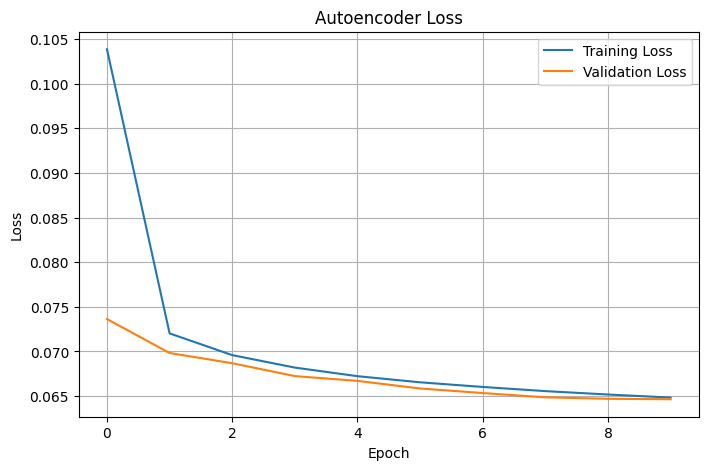

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_ae.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_ae.history["val_loss"],
    label="Validation Loss"
)

plt.title("Autoencoder Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()